# Example 1.6 — Effect of Population Size on GA Convergence

**Four Bar Mechanisms — Design with Genetic Algorithms and Neural Networks**

Open this notebook in Google Colab: [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/usuario/repo/blob/main/ex1_7_efecto_tamano_poblacion.ipynb)

In [1]:
from numpy import *
import builtins

# ── Objective function─────────────────────────────────────────────────
def pct_zona(pop, n=360):
    """(N,4) -> (N,): % of the cycle with 45° <= mu <= 135°."""
    a=pop[:,0:1]; b=pop[:,1:2]; c=pop[:,2:3]; d=pop[:,3:4]
    th2=linspace(0, 2*pi, n, endpoint=False)
    e2 = a**2 + d**2 - 2*a*d*cos(th2)
    cmu = clip((b**2 + c**2 - e2)/(2*b*c), -1., 1.)
    mu = degrees(arccos(cmu))
    return 100.*((mu >= 45.) & (mu <= 135.)).mean(axis=1)

# ── Common parameters────────────────────────────────────────────────
N_SIZES = [20, 80, 200]
N_GEN   = 100
L_MIN, L_MAX = 20., 200.
MUT_STD, P_MUT = 8., 0.25
N_SEEDS = 30        # seeds to average

results = {}
for N in N_SIZES:
    ELITE = builtins.max(2, N // 10)
    best_mat = zeros((N_SEEDS, N_GEN))
    mean_mat = zeros((N_SEEDS, N_GEN))
    for si in range(N_SEEDS):
        random.seed(si)
        pop = random.uniform(L_MIN, L_MAX, (N, 4))
        bv = -inf
        for gen in range(N_GEN):
            fit = pct_zona(pop)
            order = argsort(fit)[::-1]
            pop = pop[order]; fit = fit[order]
            if fit[0] > bv: bv = fit[0]
            best_mat[si, gen] = bv
            mean_mat[si, gen] = mean(fit)
            n_off = N - ELITE; half = builtins.max(1, N // 2)
            p1 = random.randint(0, half, n_off)
            p2 = random.randint(0, half, n_off)
            alpha = random.uniform(0, 1, (n_off, 1))
            offs  = alpha*pop[p1] + (1-alpha)*pop[p2]
            mask  = random.random((n_off, 4)) < P_MUT
            offs += mask * random.normal(0, MUT_STD, (n_off, 4))
            offs  = clip(offs, L_MIN, L_MAX)
            pop   = vstack([pop[:ELITE], offs])
    results[N] = {'best': best_mat, 'mean': mean_mat, 'elite': ELITE}

# ── Results table───────────────────────────────────────────────
print(f"{'N':>6} {'Elite':>6} {'Best (mean+-std)':>24} {'Mean':>10} {'Evals':>8}")
print("-"*60)
for N in N_SIZES:
    b = results[N]['best'][:, -1]
    m = results[N]['mean'][:, -1]
    print(f"{N:>6} {results[N]['elite']:>6} {b.mean():>10.1f}% +- {b.std():>4.1f}%  ",
          f"{m.mean():>8.1f}%  {N*N_GEN:>8,}")

print('\nGeneration in which mean>=95% (average of 30 seeds):')
for N in N_SIZES:
    gens95 = []
    for si in range(N_SEEDS):
        idx = where(results[N]['mean'][si] >= 95.)[0]
        gens95.append(idx[0]+1 if len(idx) else N_GEN+1)
    print(f"  N={N:>3}: gen {mean(gens95):.1f}  (range {min(gens95)}-{max(gens95)})")

     N  Elite         Best (mean+-std)       Mean    Evals
------------------------------------------------------------
    20      2      100.0% +-  0.0%       99.8%     2,000
    80      8      100.0% +-  0.0%       99.9%     8,000
   200     20      100.0% +-  0.0%       99.9%    20,000

Generation in which mean>=95% (average of 30 seeds):
  N= 20: gen 5.5  (range 4-11)
  N= 80: gen 7.1  (range 5-14)
  N=200: gen 8.1  (range 6-16)


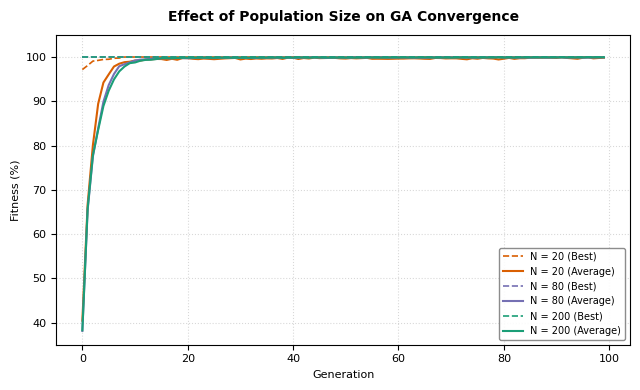

In [4]:
import os
import glob
import matplotlib.pyplot as plt

# --- AUTOMATED FILENAME SYSTEM ---
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_1.7_population_size_effect"
except Exception:
    notebook_name = "Figure_1.7_population_size_effect"

# --- SPRINGER COMPLIANT PLOT CONFIGURATION ---
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

# Size adjusted for Springer single-column / intermediate width (inches)
fig, ax = plt.subplots(figsize=(6.5, 4.0))

# Professional color palette
colors = {20: '#D95F02', 80: '#7570B3', 200: '#1B9E77'}

for N in N_SIZES:
    # Calculate mean metrics over 30 seeds
    mean_best = results[N]['best'].mean(axis=0)
    mean_avg = results[N]['mean'].mean(axis=0)

    # Plot curves with academic line-widths
    ax.plot(mean_best, label=f'N = {N} (Best)', color=colors[N], linestyle='--', linewidth=1.2)
    ax.plot(mean_avg, label=f'N = {N} (Average)', color=colors[N], linestyle='-', linewidth=1.5)

# Academic styling
ax.set_title('Effect of Population Size on GA Convergence', fontsize=10, fontweight='bold', pad=10)
ax.set_xlabel('Generation', fontsize=8)
ax.set_ylabel('Fitness (%)', fontsize=8)

# Expand y-limit slightly to avoid legend and label overlapping
ax.set_ylim(35, 105)
ax.tick_params(labelsize=8)
ax.grid(True, linestyle=':', alpha=0.3, color='gray')

# Clean and well-placed legend
ax.legend(loc='lower right', fontsize=7, frameon=True, edgecolor='gray', framealpha=0.9)

plt.tight_layout()

# --- DOUBLE EXPORT ---
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()